First five rows:
         Date    Product Region Customer_Type  Quantity  Discount  Rating  \
0  2026-01-01    Brownie  South       Regular         1         0     4.7   
1  2026-01-01  Green Tea   West           New         5        10     4.2   
2  2026-01-01  Green Tea  North           New         1        10     4.4   
3  2026-01-01      Pasta  South        Member         6         0     4.1   
4  2026-01-01  Green Tea  South           New         1         5     5.0   

   Category  Unit_Price  Revenue     Cost  Profit  
0   Dessert         120    120.0    78.28   41.72  
1  Beverage         130    585.0   295.64  289.36  
2  Beverage         130    117.0    78.74   38.26  
3      Food         250   1500.0  1043.29  456.71  
4  Beverage         130    123.5    67.73   55.77  

Dataset shape: (180, 12)

Column names:
['Date', 'Product', 'Region', 'Customer_Type', 'Quantity', 'Discount', 'Rating', 'Category', 'Unit_Price', 'Revenue', 'Cost', 'Profit']

Input features:
   Quantity  D

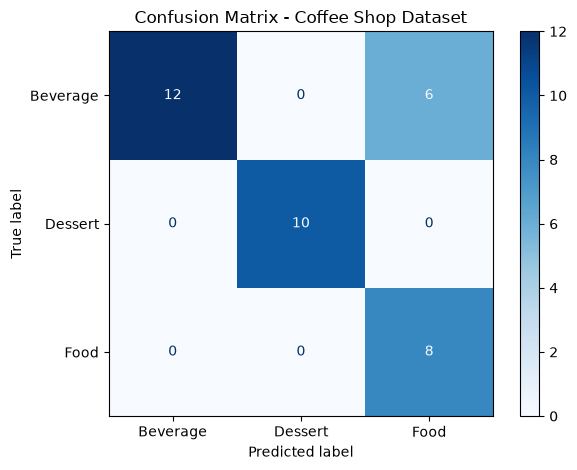

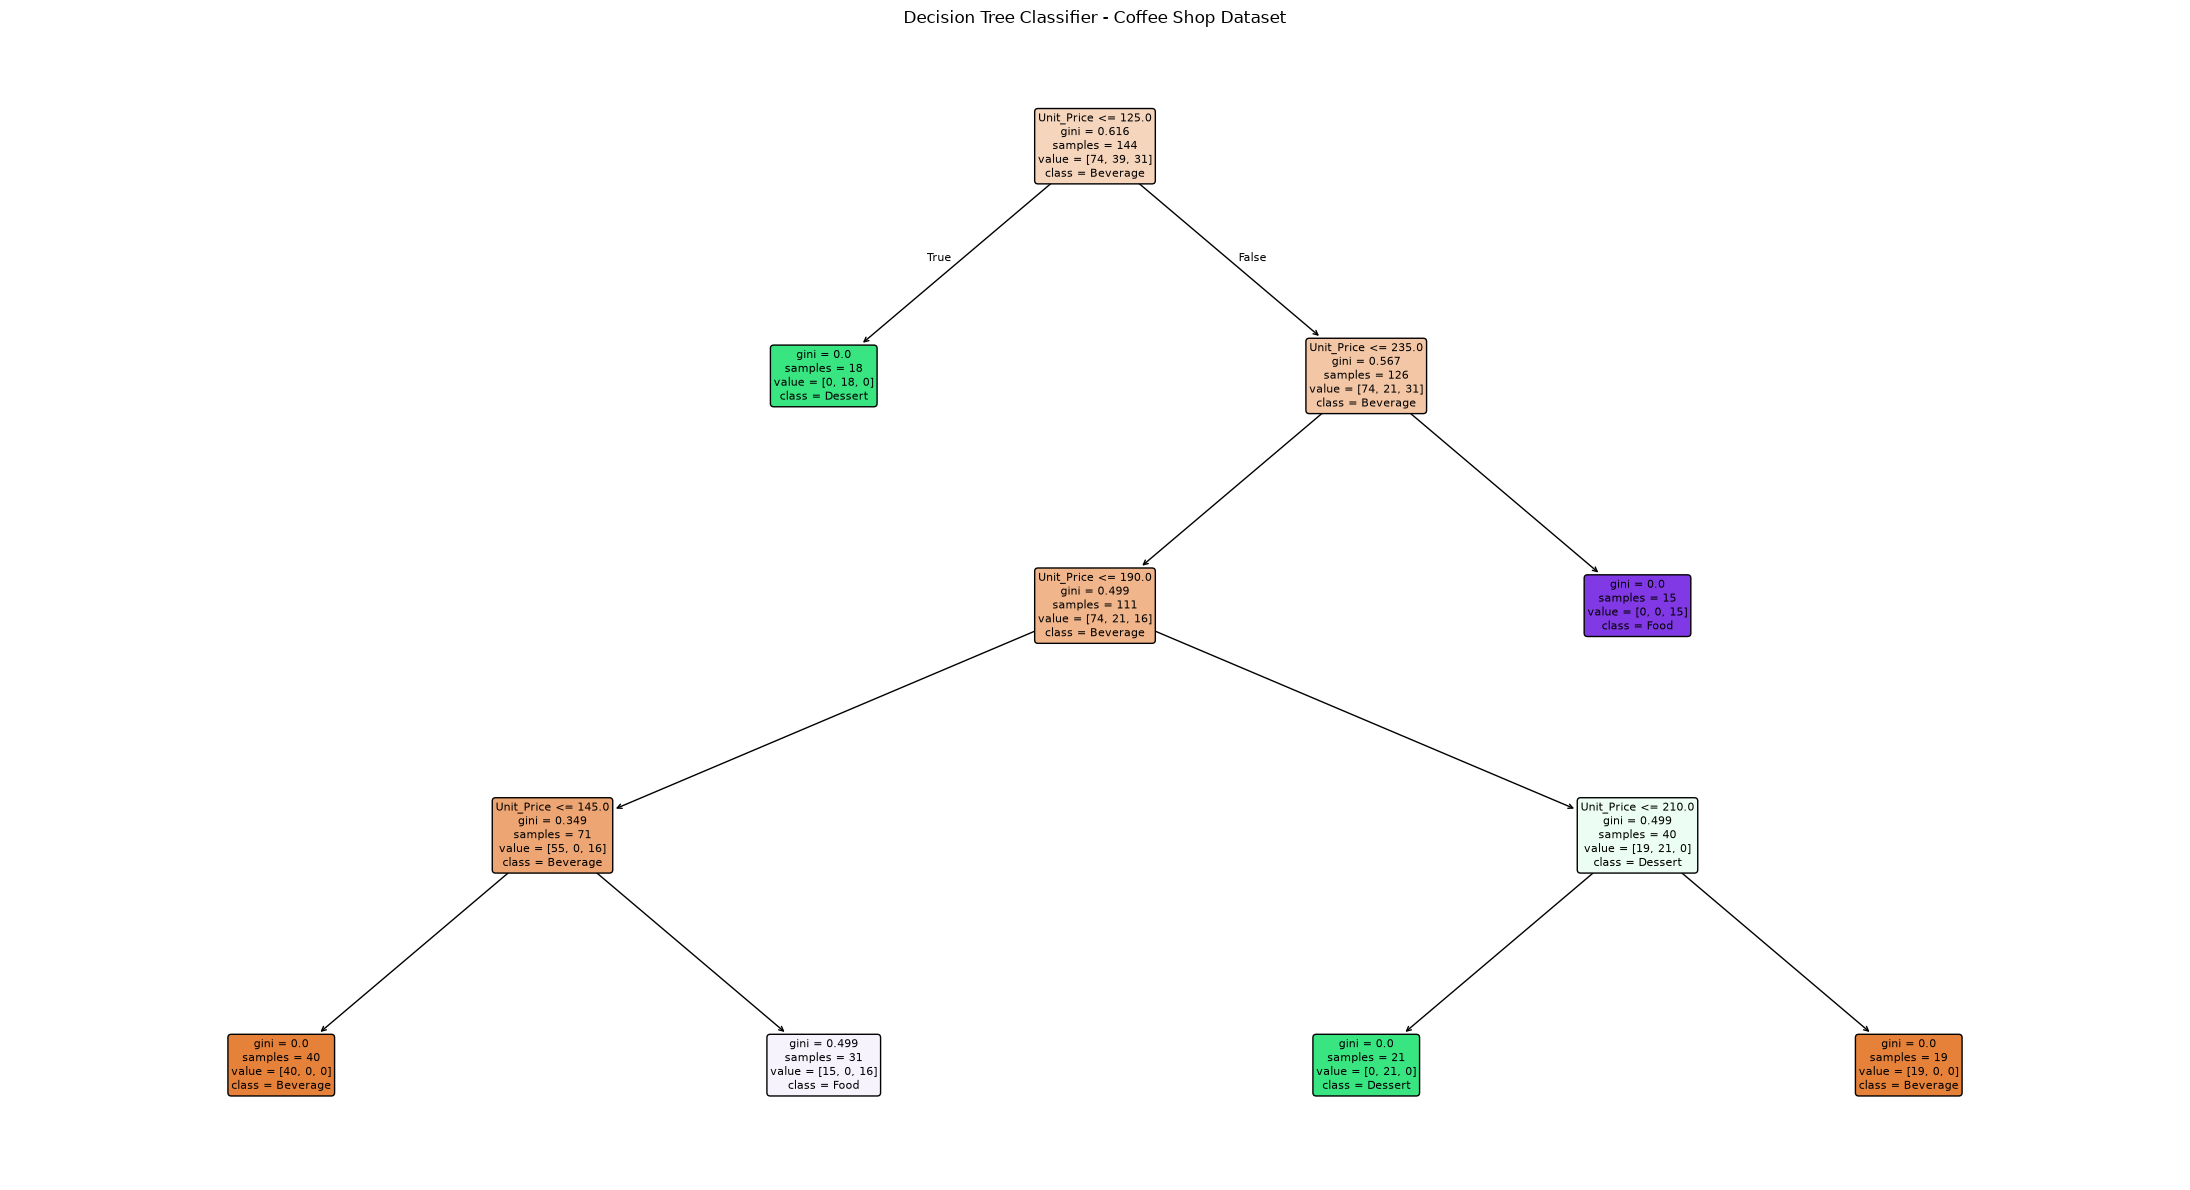

In [8]:

# ============================================================
# 1. Import the required libraries
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# 2. Load the coffee shop dataset
# ============================================================

# Make sure coffe_shop.csv is in the same folder as this file
df = pd.read_csv("coffe_shop.csv")

# Remove the extra index column if it exists
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# ============================================================
# 3. Prepare the data
# ============================================================

# Convert Date into useful numerical features
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["DayOfWeek"] = df["Date"].dt.dayofweek

# Remove Date because we extracted its useful components
df = df.drop(columns=["Date"])

# Select the target variable
# We want to predict the product Category
y = df["Category"]

# Select input features
# Drop Category and Product to avoid directly using
# the product's name to determine its category
X = df.drop(columns=["Category", "Product"])

# Encode categorical input columns
X = pd.get_dummies(
    X,
    columns=["Region", "Customer_Type"],
    dtype=int
)

# Encode target labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

print("\nInput features:")
print(X.head())

print("\nTarget classes:", label_encoder.classes_)

# ============================================================
# 4. Split the dataset into training and testing sets
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# ============================================================
# 5. Create and train the Decision Tree model
# ============================================================

model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

print("\nDecision Tree model trained successfully!")

# ============================================================
# 6. Make predictions
# ============================================================

y_pred = model.predict(X_test)

print("\nActual categories:")
print(label_encoder.inverse_transform(y_test))

print("\nPredicted categories:")
print(label_encoder.inverse_transform(y_pred))

# ============================================================
# 7. Evaluate the model
# ============================================================

accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(len(label_encoder.classes_))),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(range(len(label_encoder.classes_)))
)

print("\nConfusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
).plot(cmap="Blues")

plt.title("Confusion Matrix - Coffee Shop Dataset")
plt.tight_layout()
plt.show()

# ============================================================
# 8. Visualize the Decision Tree
# ============================================================

plt.figure(figsize=(22, 12))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=label_encoder.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Classifier - Coffee Shop Dataset")
plt.tight_layout()
plt.show()
